<a href="https://colab.research.google.com/github/joumana-wael/Deep-Learning/blob/main/notebooks/EDA(DL).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install -q datasets matplotlib

In [3]:
from datasets import load_dataset

raw_train = load_dataset("Multimodal-Fatima/CUB_train",split="train",)

print(raw_train)
print("\nFeatures:")
print(raw_train.features)

README.md:   0%|          | 0.00/7.16k [00:00<?, ?B/s]

data/train-00000-of-00002-5e7d350dbc117c(…): reconstructing file:   0%|          |  0.00B /  287MB            

data/train-00000-of-00002-5e7d350dbc117c(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-ae08e95fea856c(…): reconstructing file:   0%|          |  0.00B /  297MB            

data/train-00001-of-00002-ae08e95fea856c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5994 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'description', 'label', 'file_name', 'id'],
    num_rows: 5994
})

Features:
{'image': Image(mode=None, decode=True), 'description': Value('string'), 'label': ClassLabel(names=['Black footed Albatross', 'Laysan Albatross', 'Sooty Albatross', 'Groove billed Ani', 'Crested Auklet', 'Least Auklet', 'Parakeet Auklet', 'Rhinoceros Auklet', 'Brewer Blackbird', 'Red winged Blackbird', 'Rusty Blackbird', 'Yellow headed Blackbird', 'Bobolink', 'Indigo Bunting', 'Lazuli Bunting', 'Painted Bunting', 'Cardinal', 'Spotted Catbird', 'Gray Catbird', 'Yellow breasted Chat', 'Eastern Towhee', 'Chuck will Widow', 'Brandt Cormorant', 'Red faced Cormorant', 'Pelagic Cormorant', 'Bronzed Cowbird', 'Shiny Cowbird', 'Brown Creeper', 'American Crow', 'Fish Crow', 'Black billed Cuckoo', 'Mangrove Cuckoo', 'Yellow billed Cuckoo', 'Gray crowned Rosy Finch', 'Purple Finch', 'Northern Flicker', 'Acadian Flycatcher', 'Great Crested Flycatcher', 'Least Flycatcher', 'Olive sided Flyc

In [4]:
sample = raw_train[0]
label_info = raw_train.features["label"]

print("Image ID:", sample["id"])
print("Filename:", sample["file_name"])
print("Label ID:", sample["label"])
print("Species:", label_info.int2str(sample["label"]))
print("Image size (width, height):", sample["image"].size)
print("Image mode:", sample["image"].mode)

print("\nRaw description:")
print(repr(sample["description"]))

Image ID: 0
Filename: Black_Footed_Albatross_0007_796138.jpg
Label ID: 0
Species: Black footed Albatross
Image size (width, height): (500, 301)
Image mode: RGB

Raw description:
'this bird is brown with a lighter brown crest.\naquatic large bird with long hooked bill, white face, and brown body.\nbird has brown body feathers, brown breast feathers, and brown beak\nthis bird has a white superciliary and brown all around its body with a long bill\nthis is a brown bird with a white face and a long downward pointing beak.\nthis bird is brown with white and has a long, pointy beak.\nbrown duck playing on the lake making a poodle\nthis bird has wings that are brown and has a long bill\nthis bird has long brown bill, with a brown body.\nthis is a medium sized brown bird, with a long pointed bill.\n'


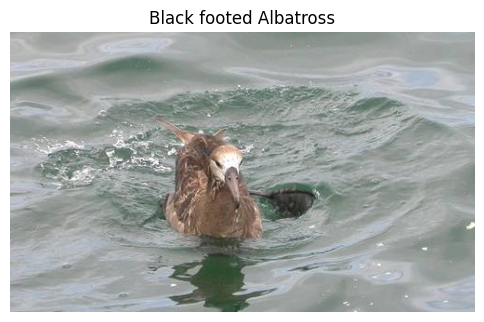

Number of lines: 10
Number of blank lines: 0
1: 'this bird is brown with a lighter brown crest.'
2: 'aquatic large bird with long hooked bill, white face, and brown body.'
3: 'bird has brown body feathers, brown breast feathers, and brown beak'
4: 'this bird has a white superciliary and brown all around its body with a long bill'
5: 'this is a brown bird with a white face and a long downward pointing beak.'
6: 'this bird is brown with white and has a long, pointy beak.'
7: 'brown duck playing on the lake making a poodle'
8: 'this bird has wings that are brown and has a long bill'
9: 'this bird has long brown bill, with a brown body.'
10: 'this is a medium sized brown bird, with a long pointed bill.'


In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.imshow(sample["image"])
plt.title(label_info.int2str(sample["label"]))
plt.axis("off")
plt.show()

description = sample["description"]

if isinstance(description, str):
    lines = description.splitlines()

    print("Number of lines:", len(lines))
    print("Number of blank lines:", sum(not line.strip() for line in lines))

    for number, line in enumerate(lines, start=1):
        print(f"{number}: {line!r}")
else:
    print("Unexpected description value:", description)

Initial inspection found a valid RGB image and ten nonempty captions. A caption contains potentially inaccurate or malformed wording. We will measure caption issues across the dataset before choosing a cleaning policy.

Purpose: To understand the structure of a single record before designing any preprocessing for the whole dataset.

What it does: The cell displays the first training image with its species label (Black footed Albatross). It then takes the description field, which is stored as one string, and splits it into separate lines with splitlines(). It prints the number of lines, the number of blank lines, and each caption using repr(), so that hidden characters such as \n stay visible.

Findings: The description of this sample contains exactly 10 non-blank captions, one per line, which matches the dataset documentation. The captions vary a lot in style and detail. Some are generic (“this bird is brown with a lighter brown crest”), while others describe specific parts such as the bill, the face, or the superciliary. Caption 7 (“brown duck playing on the lake making a poodle”) is odd and looks like a noisy or low-quality annotation.

Conclusion and next step: Splitting on newlines separates the ten captions correctly for this sample. This is only one record, so it is not yet proof that the same holds for the whole dataset. The next step is to run the same check on every record (caption count per image, blank lines, length, and unusual characters), and to treat the odd captions as noise to be quantified in the caption EDA.


Number of images: 5994
Number of defined classes: 200
Number of represented classes: 200
Smallest class: 29 images
Largest class: 30 images
Mean images per class: 29.97
Largest/smallest class ratio: 1.03

Five smallest classes:
Common Raven: 29
Nelson Sharp tailed Sparrow: 29
Bank Swallow: 29
Artic Tern: 29
Red cockaded Woodpecker: 29

Five largest classes:
Black footed Albatross: 30
Laysan Albatross: 30
Sooty Albatross: 30
Groove billed Ani: 30
Crested Auklet: 30


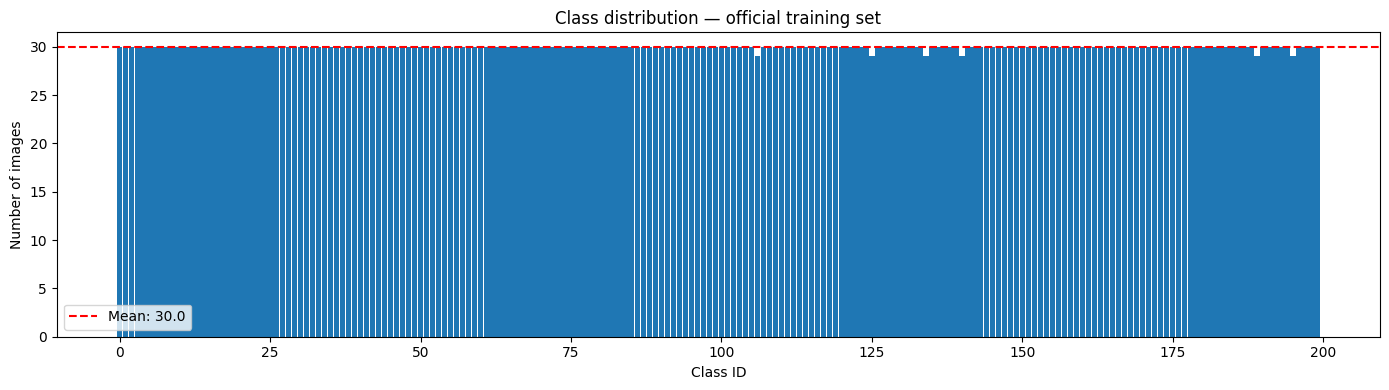

In [6]:
import numpy as np
import matplotlib.pyplot as plt

label_info = raw_train.features["label"]
class_names = label_info.names
num_classes = len(class_names)

labels = np.asarray(raw_train["label"], dtype=np.int64)

# Check that all labels are valid class IDs.
assert labels.min() >= 0
assert labels.max() < num_classes

counts = np.bincount(labels, minlength=num_classes)

print("Number of images:", len(labels))
print("Number of defined classes:", num_classes)
print("Number of represented classes:", np.count_nonzero(counts))
print("Smallest class:", counts.min(), "images")
print("Largest class:", counts.max(), "images")
print("Mean images per class:", round(counts.mean(), 2))

if counts.min() > 0:
    print("Largest/smallest class ratio:",
          round(counts.max() / counts.min(), 2))
else:
    print("Some defined classes have no images.")

print("\nFive smallest classes:")
for class_id in np.argsort(counts, kind="stable")[:5]:
    print(f"{class_names[class_id]}: {counts[class_id]}")

print("\nFive largest classes:")
for class_id in np.argsort(-counts, kind="stable")[:5]:
    print(f"{class_names[class_id]}: {counts[class_id]}")

fig, ax = plt.subplots(figsize=(14, 4))

ax.bar(np.arange(num_classes), counts, width=0.9)
ax.axhline(
    counts.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {counts.mean():.1f}",
)

ax.set(
    title="Class distribution — official training set",
    xlabel="Class ID",
    ylabel="Number of images",
)
ax.legend()
plt.tight_layout()
plt.show()

The official training set contains 5,994 images across 200 species, with 29–30 images per species and a maximum-to-minimum count ratio of approximately 1.03. No class-balancing intervention is planned for the baseline.
Purpose: To check whether the classes are balanced, because this affects the choice of training strategy and evaluation metrics.

What it does: The cell reads all labels from the training set and checks that each is a valid class ID (0 to 199). It counts the images per class with np.bincount and prints summary statistics: the number of defined and represented classes, the smallest and largest class sizes, the mean, and the largest-to-smallest ratio. It also lists the five smallest and five largest classes. A bar chart then shows the count for each class ID, with a dashed line at the mean.

Findings: All 200 classes are present in the 5,994 training images. Each class has either 29 or 30 images (mean 29.97), so the largest/smallest ratio is only 1.03. The plot shows nearly all bars at the same height, with a few classes at 29.

Conclusion: The training set is almost perfectly balanced, so no class weighting, oversampling, or undersampling is needed to correct imbalance. The main difficulty is the opposite problem: with only about 30 images per class, a model trained from scratch is likely to overfit. This motivates strong data augmentation and makes transfer learning an important comparison. The thin white gaps between bars in the plot come from drawing 200 narrow bars and do not mean missing classes, since the counts confirm that every class is represented.

In [7]:
from collections import Counter
import numpy as np

image_stats = []
image_errors = []

# Access filenames separately so a decoding failure won't hide the filename.
file_names = list(raw_train["file_name"])

for index in range(len(raw_train)):
    try:
        image = raw_train[index]["image"]
        image.load()  # Force full decoding, not just reading the image header.

        width, height = image.size

        if width <= 0 or height <= 0:
            raise ValueError(f"Invalid dimensions: {image.size}")

        image_stats.append({
            "index": index,
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "mode": image.mode,
        })

    except Exception as error:
        image_errors.append({
            "index": index,
            "file_name": file_names[index],
            "error": f"{type(error).__name__}: {error}",
        })

    if (index + 1) % 1000 == 0:
        print(f"Checked {index + 1}/{len(raw_train)} images")

print("\nSuccessfully decoded:", len(image_stats))
print("Failed to decode:", len(image_errors))
print("Color modes:", dict(Counter(row["mode"] for row in image_stats)))

if image_stats:
    widths = np.array([row["width"] for row in image_stats])
    heights = np.array([row["height"] for row in image_stats])
    ratios = np.array([row["aspect_ratio"] for row in image_stats])

    for name, values in [
        ("Width (pixels)", widths),
        ("Height (pixels)", heights),
        ("Aspect ratio (width/height)", ratios),
    ]:
        print(
            f"{name}: min={values.min():.2f}, "
            f"median={np.median(values):.2f}, "
            f"max={values.max():.2f}"
        )

if image_errors:
    print("\nFirst five failures:")
    for error in image_errors[:5]:
        print(error)

Checked 1000/5994 images
Checked 2000/5994 images
Checked 3000/5994 images
Checked 4000/5994 images
Checked 5000/5994 images

Successfully decoded: 5994
Failed to decode: 0
Color modes: {'RGB': 5990, 'L': 4}
Width (pixels): min=121.00, median=500.00, max=500.00
Height (pixels): min=120.00, median=375.00, max=500.00
Aspect ratio (width/height): min=0.49, median=1.33, max=3.60


Purpose: To verify image integrity and measure image sizes and color modes before designing the preprocessing pipeline.
What it does: Each of the 5,994 training images is decoded one at a time, with full decoding forced so corrupted files are caught. Width, height, aspect ratio and color mode are recorded, and failures are logged with their file names.
Findings: All images decoded successfully, so there are no corrupted files. 5,990 images are RGB and 4 are grayscale. Widths range from 121 to 500 pixels (median 500) and heights from 120 to 500 (median 375). Aspect ratios range from 0.49 to 3.60 with a median of 1.33.
Conclusion: Images must be converted to a common 3-channel format and resized to a fixed input size, and the resizing method must account for the wide range of aspect ratios. The four grayscale images are also noted for exclusion or special handling in the colorization task.

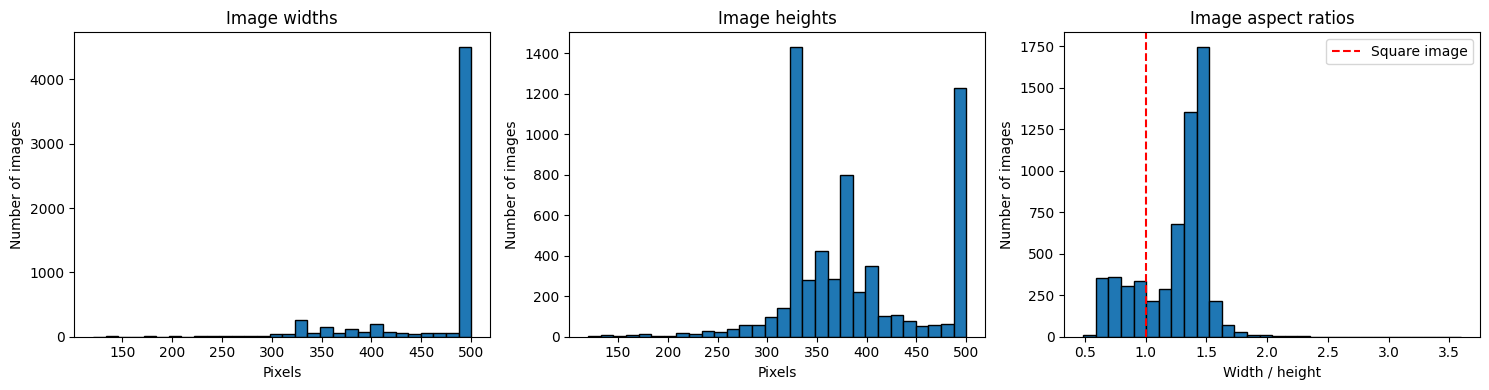

In [8]:
import matplotlib.pyplot as plt

if image_stats:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, values, title, xlabel in [
        (axes[0], widths, "Image widths", "Pixels"),
        (axes[1], heights, "Image heights", "Pixels"),
        (axes[2], ratios, "Image aspect ratios", "Width / height"),
    ]:
        ax.hist(values, bins=30, edgecolor="black")
        ax.set(title=title, xlabel=xlabel, ylabel="Number of images")

    axes[2].axvline(1.0, color="red", linestyle="--", label="Square image")
    axes[2].legend()

    plt.tight_layout()
    plt.show()

How this will guide preprocessing
- Different image sizes → we need a consistent input-sizing strategy for batching.
- Different aspect ratios → we should compare resizing, cropping, or padding carefully; directly stretching everything into a square can distort birds.
- Non-RGB images → inspect them and establish a consistent three-channel conversion.
- Decoding failures → inspect the errors before deciding whether records need repair or exclusion.
Successful decoding only confirms readability; it does not prove that an image is sharp, correctly labeled, or otherwise high quality.

Purpose: To visualize the distribution of image sizes and aspect ratios so that the resizing strategy can be chosen from evidence.
What it does: Three histograms show the width, height, and aspect ratio of all 5,994 training images, with a dashed line marking a square image (ratio 1.0).
Findings: Most images have a width of exactly 500 pixels, while heights concentrate around 333, 375, and 500 pixels. The aspect ratio distribution is bimodal: most images are landscape (ratio around 1.3 to 1.5), and a smaller group is portrait (ratio around 0.6 to 0.9). Very wide or very small images are rare.
Conclusion: Images do not share one shape, so they must be resized to a fixed input size. Because both orientations are common, a plain center crop could cut off parts of the bird differently depending on orientation. This favors a resizing approach that preserves the whole subject (such as resizing with padding), or at least checking how often a crop removes the bird. This will be tested in the preprocessing step.

Row 726 | ID 726 | Pelagic_Cormorant_0022_23802.jpg
Row 1868 | ID 1868 | Ivory_Gull_0040_49180.jpg
Row 1950 | ID 1950 | Western_Gull_0002_54825.jpg
Row 2764 | ID 2764 | Clark_Nutcracker_0020_85099.jpg
Row 3228 | ID 3228 | White_Necked_Raven_0044_797348.jpg
Row 5590 | ID 5590 | American_Three_Toed_Woodpecker_0021_179832.jpg


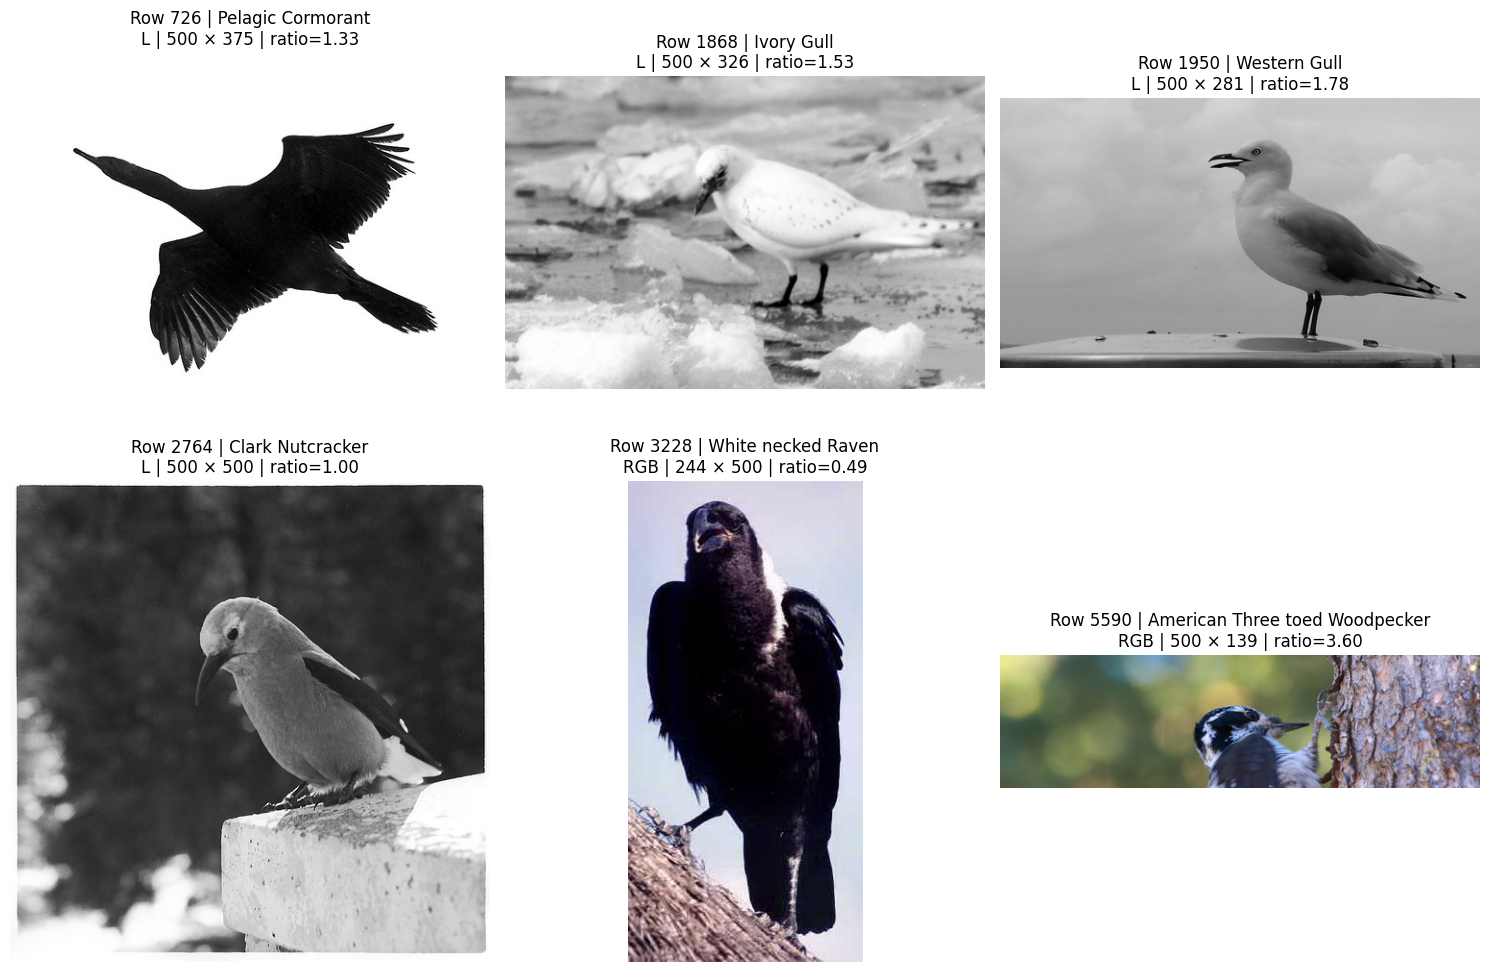

In [9]:
# Gather non-RGB images and the two aspect-ratio extremes.
non_rgb = [row for row in image_stats if row["mode"] != "RGB"]

extremes = [
    min(image_stats, key=lambda row: row["aspect_ratio"]),
    max(image_stats, key=lambda row: row["aspect_ratio"]),
]

# Avoid displaying a record twice if it belongs to both groups.
selected = list({
    row["index"]: row
    for row in non_rgb + extremes
}.values())

ncols = 3
nrows = (len(selected) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(15, 5 * nrows),
    squeeze=False,
)

for ax in axes.flat:
    ax.axis("off")

for ax, stats in zip(axes.flat, selected):
    record = raw_train[stats["index"]]
    species = label_info.int2str(record["label"])

    # RGB conversion is for consistent display; the original is unchanged.
    ax.imshow(record["image"].convert("RGB"))
    ax.set_title(
        f"Row {stats['index']} | {species}\n"
        f"{stats['mode']} | {stats['width']} × {stats['height']} | "
        f"ratio={stats['aspect_ratio']:.2f}"
    )

    print(
        f"Row {stats['index']} | ID {record['id']} | "
        f"{record['file_name']}"
    )

plt.tight_layout()
plt.show()

All 5,994 training images decoded successfully. Four grayscale images were visually inspected and retained for classification. Aspect ratios ranged from 0.49 to 3.60. We selected proportional resizing with padding as the initial sizing strategy to preserve the visible image content.


In [10]:
from collections import Counter
import re
import numpy as np
import matplotlib.pyplot as plt

descriptions = list(raw_train["description"])

captions_by_image = []
caption_issues = []
caption_lengths = []

for index, description in enumerate(descriptions):
    if not isinstance(description, str):
        captions_by_image.append([])
        caption_issues.append({
            "index": index,
            "issue": "Missing or non-string description",
        })
        continue

    lines = description.splitlines()
    blank_count = sum(not line.strip() for line in lines)

    # Separate analysis copy: trim surrounding whitespace and omit empty lines.
    captions = [line.strip() for line in lines if line.strip()]
    captions_by_image.append(captions)

    # Exact repetitions after trimming surrounding whitespace.
    duplicate_count = len(captions) - len(set(captions))

    if len(captions) != 10 or blank_count > 0 or duplicate_count > 0:
        caption_issues.append({
            "index": index,
            "caption_count": len(captions),
            "blank_lines": blank_count,
            "extra_duplicate_captions": duplicate_count,
        })

    for caption in captions:
        # Simple word-count convention for EDA, not our final tokenizer.
        words = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", caption)
        caption_lengths.append(len(words))

caption_counts = [len(captions) for captions in captions_by_image]

print("Images inspected:", len(descriptions))
print("Total nonempty captions:", sum(caption_counts))
print("Caption-count distribution:", dict(sorted(Counter(caption_counts).items())))
print("Images flagged for review:", len(caption_issues))

if caption_lengths:
    lengths = np.array(caption_lengths)

    print("\nWords per caption:")
    print("Minimum:", lengths.min())
    print("Median:", np.median(lengths))
    print("Mean:", round(lengths.mean(), 2))
    print("95th percentile:", round(np.percentile(lengths, 95), 2))
    print("Maximum:", lengths.max())
    print("Nonempty captions with zero detected words:", np.sum(lengths == 0))

print("\nFirst ten flagged records:")
for issue in caption_issues[:10]:
    print(issue)

Images inspected: 5994
Total nonempty captions: 59940
Caption-count distribution: {10: 5994}
Images flagged for review: 583

Words per caption:
Minimum: 1
Median: 14.0
Mean: 15.28
95th percentile: 24.0
Maximum: 66
Nonempty captions with zero detected words: 0

First ten flagged records:
{'index': 20, 'caption_count': 10, 'blank_lines': 0, 'extra_duplicate_captions': 2}
{'index': 29, 'caption_count': 10, 'blank_lines': 0, 'extra_duplicate_captions': 1}
{'index': 46, 'caption_count': 10, 'blank_lines': 0, 'extra_duplicate_captions': 2}
{'index': 64, 'caption_count': 10, 'blank_lines': 0, 'extra_duplicate_captions': 1}
{'index': 68, 'caption_count': 10, 'blank_lines': 0, 'extra_duplicate_captions': 1}
{'index': 109, 'caption_count': 10, 'blank_lines': 0, 'extra_duplicate_captions': 2}
{'index': 114, 'caption_count': 10, 'blank_lines': 0, 'extra_duplicate_captions': 1}
{'index': 115, 'caption_count': 10, 'blank_lines': 0, 'extra_duplicate_captions': 1}
{'index': 117, 'caption_count': 10, '

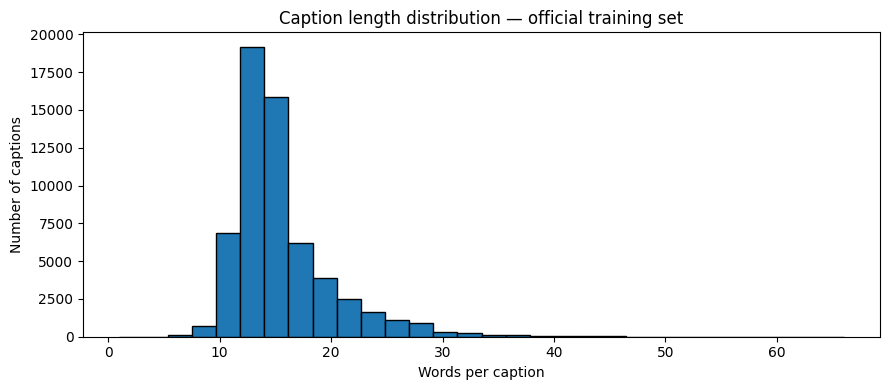

In [11]:
if caption_lengths:
    plt.figure(figsize=(9, 4))
    plt.hist(caption_lengths, bins=30, edgecolor="black")
    plt.xlabel("Words per caption")
    plt.ylabel("Number of captions")
    plt.title("Caption length distribution — official training set")
    plt.tight_layout()
    plt.show()

In [12]:
from collections import Counter

duplicate_rows = []
extra_duplicate_total = 0

for index, captions in enumerate(captions_by_image):
    frequencies = Counter(captions)
    repeated = {
        caption: count
        for caption, count in frequencies.items()
        if count > 1
    }

    if repeated:
        duplicate_rows.append((index, repeated))
        extra_duplicate_total += sum(
            count - 1 for count in repeated.values()
        )

blank_line_rows = sum(
    isinstance(description, str)
    and any(not line.strip() for line in description.splitlines())
    for description in descriptions
)

print("Images with repeated captions:", len(duplicate_rows))
print("Extra duplicate occurrences:", extra_duplicate_total)
print("Images containing blank lines:", blank_line_rows)

print("\nExample repeated captions:")
for index, repeated in duplicate_rows[:3]:
    print(f"\nRow {index} | {file_names[index]}")
    for caption, count in repeated.items():
        print(f"  Appears {count} times: {caption!r}")

Images with repeated captions: 583
Extra duplicate occurrences: 639
Images containing blank lines: 0

Example repeated captions:

Row 20 | Black_Footed_Albatross_0067_170.jpg
  Appears 3 times: 'this bird is brown with white and has a long, pointy beak.'

Row 29 | Black_Footed_Albatross_0089_796069.jpg
  Appears 2 times: 'this bird is brown in color, with a large curved beak.'

Row 46 | Laysan_Albatross_0065_809.jpg
  Appears 3 times: 'this bird has wings that are grey and has a white belly'


Purpose: To remove redundant and unusable captions while keeping a full record of every change.
What it does: For each image, exact repeated captions are removed (the first occurrence is kept), and one manually confirmed incomplete caption (the single word “this” at row 1171) is excluded. All removals are written to a log with the image, text and reason. The raw dataset is left unchanged.
Findings: 640 of 59,940 captions (1.07%) were removed: 639 exact within-image duplicates and 1 incomplete caption. No image lost all its captions, so every image still has at least one caption.
Conclusion: The cleaned set contains 59,300 captions. Images now have a variable number of captions (at most 10), which the captioning data loader must handle. Duplicates were removed per image only, so that no sentence is over-weighted during training without deleting sentences that legitimately describe other birds.

In [13]:
import re

word_counts = Counter()
caption_records = []

for index, captions in enumerate(captions_by_image):
    for caption_number, caption in enumerate(captions, start=1):
        words = re.findall(
            r"[A-Za-z]+(?:'[A-Za-z]+)?",
            caption.lower(),
        )
        word_counts.update(words)

        caption_records.append({
            "index": index,
            "caption_number": caption_number,
            "text": caption,
            "length": len(words),
        })

print("Distinct word types:", len(word_counts))
print("Total word occurrences:", sum(word_counts.values()))
print("Word types occurring only once:",
      sum(count == 1 for count in word_counts.values()))

print("\n20 most frequent words:")
for word, count in word_counts.most_common(20):
    print(f"{word}: {count}")

# Alphabetical sample for inspection—not a list of confirmed typos.
singletons = sorted(
    word for word, count in word_counts.items() if count == 1
)
print("\nSample of words occurring once:")
print(singletons[:30])

ordered = sorted(caption_records, key=lambda row: row["length"])

for heading, examples in [
    ("Three shortest captions", ordered[:3]),
    ("Three longest captions", ordered[-3:]),
]:
    print(f"\n{heading}:")
    for row in examples:
        print(
            f"Row {row['index']} | Caption {row['caption_number']} | "
            f"{row['length']} words\n{row['text']}\n"
        )

Distinct word types: 4067
Total word occurrences: 915938
Word types occurring only once: 1867

20 most frequent words:
a: 90704
and: 82990
bird: 58798
with: 40957
has: 40560
black: 39789
this: 37815
white: 33207
brown: 21772
is: 20969
beak: 18714
belly: 17426
small: 16860
wings: 15907
yellow: 15774
the: 15470
bill: 14701
long: 10939
grey: 10563
breast: 10204

Sample of words occurring once:
['aalso', 'aare', 'abd', 'abdobmen', 'abdomenal', 'abdomend', 'abdomin', 'abdomon', 'ablack', 'ablaze', 'abright', 'abruptly', 'abundant', 'abuts', 'accentuating', 'ace', 'ack', 'acrown', 'acting', 'actual', 'actually', 'adabomin', 'add', 'additional', 'additiont', 'adjacent', 'adult', "adult's", 'adults', 'afloat']

Three shortest captions:
Row 1171 | Caption 8 | 1 words
this

Row 5556 | Caption 2 | 3 words
the colorful bird

Row 1465 | Caption 3 | 4 words
a large black bird.


Three longest captions:
Row 5564 | Caption 5 | 64 words
this small bird has a brown head with a raised tuft on the top of 

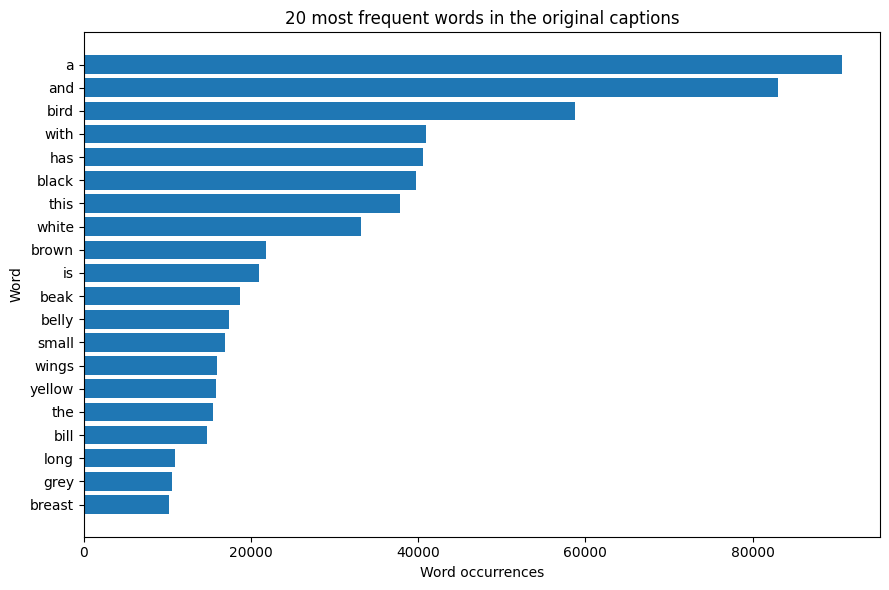

In [19]:
top_words = word_counts.most_common(20)
words, frequencies = zip(*top_words)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(words[::-1], frequencies[::-1])
ax.set(
    title="20 most frequent words in the original captions",
    xlabel="Word occurrences",
    ylabel="Word",
)
plt.tight_layout()
plt.show()

Purpose: To measure the vocabulary and caption length extremes in order to decide how the text will be tokenized and how rare words will be handled.
What it does: Captions are lowercased and split into words with a simple regular expression (letters and internal apostrophes only), and word frequencies are counted. The shortest and longest captions are printed for manual inspection.
Findings: [Update with the numbers from the cleaned captions.] The vocabulary has about 4,000 distinct words in about 916,000 occurrences. The most frequent words are function words and basic descriptors (a, and, bird, with, black, white). About 46% of the word types occur only once, but they make up about 0.2% of all occurrences. A sample of these contains misspellings (for example several spellings of “abdomen”), words joined together (for example “ablack”), and genuine rare words. The longest captions (64 to 66 words) are well-formed but run-on sentences.
Conclusion: The language is repetitive and visual, which suits a small decoder vocabulary. Rare words need a policy (minimum frequency or correction), the maximum caption length must be chosen from the length distribution, and the vocabulary must be built from the training split only.

In [14]:
cleaned_captions_by_image = []
caption_cleaning_log = []

# A specific exclusion supported by our manual inspection.
# Row indices refer to the unchanged raw_train dataset.
confirmed_exclusions = {
    (1171, "this"): "Incomplete caption with no visual description"
}

for index, captions in enumerate(captions_by_image):
    kept = []
    seen = set()

    for caption_number, caption in enumerate(captions, start=1):
        exclusion_reason = confirmed_exclusions.get((index, caption))

        if exclusion_reason is not None:
            reason = exclusion_reason
        elif caption in seen:
            reason = "Exact duplicate within the same image"
        else:
            kept.append(caption)
            seen.add(caption)
            continue

        caption_cleaning_log.append({
            "index": index,
            "file_name": file_names[index],
            "parsed_caption_number": caption_number,
            "text": caption,
            "reason": reason,
        })

    cleaned_captions_by_image.append(kept)

before = sum(map(len, captions_by_image))
after = sum(map(len, cleaned_captions_by_image))

print("Captions before:", before)
print("Captions after:", after)
print("Removed entries:", before - after)
print("Removal reasons:", dict(Counter(
    entry["reason"] for entry in caption_cleaning_log
)))
print("Images with no remaining captions:", sum(
    len(captions) == 0 for captions in cleaned_captions_by_image
))

assert len(cleaned_captions_by_image) == len(raw_train)
assert before - after == len(caption_cleaning_log)

Captions before: 59940
Captions after: 59300
Removed entries: 640
Removal reasons: {'Exact duplicate within the same image': 639, 'Incomplete caption with no visual description': 1}
Images with no remaining captions: 0


In [15]:
from collections import Counter

for column in ["id", "file_name"]:
    counts = Counter(raw_train[column])
    repeated = {
        value: count
        for value, count in counts.items()
        if count > 1
    }

    print(f"\n{column}:")
    print("Number of repeated values:", len(repeated))
    print("Extra occurrences:", sum(count - 1 for count in repeated.values()))
    print("Examples:", list(repeated.items())[:5])


id:
Number of repeated values: 0
Extra occurrences: 0
Examples: []

file_name:
Number of repeated values: 0
Extra occurrences: 0
Examples: []


Purpose: To check that each record is unique at the metadata level.
What it does: Counts how often each id and each file_name occurs in the training set and reports any value that repeats.
Findings: No id and no file_name is repeated, so there are no duplicated records by metadata.
Conclusion: Records are unique by identifier. This does not rule out visually identical images stored under different names, so an image-hash check is performed separately, along with a check for overlap between the training and test splits.

In [16]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)
hash_errors = []

labels = list(raw_train["label"])
file_names = list(raw_train["file_name"])

for index in range(len(raw_train)):
    try:
        image = raw_train[index]["image"].convert("RGB")
        image.load()

        fingerprint = hashlib.sha256()

        # Include dimensions so differently shaped images are distinguished.
        fingerprint.update(
            f"{image.width}x{image.height}|RGB|".encode("ascii")
        )
        fingerprint.update(image.tobytes())

        hash_groups[fingerprint.hexdigest()].append(index)

    except Exception as error:
        hash_errors.append({
            "index": index,
            "error": f"{type(error).__name__}: {error}",
        })

    if (index + 1) % 1000 == 0:
        print(f"Checked {index + 1}/{len(raw_train)} images")

duplicate_image_groups = [
    indices
    for indices in hash_groups.values()
    if len(indices) > 1
]

conflicting_label_groups = [
    indices
    for indices in duplicate_image_groups
    if len({labels[index] for index in indices}) > 1
]

print("\nImages successfully checked:",
      sum(len(indices) for indices in hash_groups.values()))
print("Checking failures:", len(hash_errors))
print("Exact duplicate groups:", len(duplicate_image_groups))
print("Extra image copies:",
      sum(len(indices) - 1 for indices in duplicate_image_groups))
print("Duplicate groups with conflicting labels:",
      len(conflicting_label_groups))

print("\nFirst five duplicate groups:")
for group_number, indices in enumerate(duplicate_image_groups[:5], start=1):
    print(f"\nGroup {group_number}:")
    for index in indices:
        species = raw_train.features["label"].int2str(labels[index])
        print(f"  Row {index} | {species} | {file_names[index]}")

if hash_errors:
    print("\nFirst five checking failures:")
    print(hash_errors[:5])

Checked 1000/5994 images
Checked 2000/5994 images
Checked 3000/5994 images
Checked 4000/5994 images
Checked 5000/5994 images

Images successfully checked: 5994
Checking failures: 0
Exact duplicate groups: 1
Extra image copies: 1
Duplicate groups with conflicting labels: 0

First five duplicate groups:

Group 1:
  Row 1712 | Pigeon Guillemot | Pigeon_Guillemot_0018_40195.jpg
  Row 1731 | Pigeon Guillemot | Pigeon_Guillemot_0081_40339.jpg


Purpose: To detect duplicated images that would not be found by comparing identifiers.
What it does: Each training image is converted to RGB, and a SHA-256 hash of its dimensions and pixel data is computed. Images with the same hash are grouped, and each group is checked for conflicting class labels.
Findings: All 5,994 images were checked without error. One group of two identical images was found (rows 1712 and 1731, both Pigeon Guillemot, with different file names). No duplicate group has conflicting labels.
Conclusion: The training set contains one exact duplicate (0.017% of images). Its effect on training is negligible, but one copy is removed so that identical images cannot appear on both sides of the training/validation split. Only exact duplicates were checked, so near-duplicates (resized or re-compressed copies) would not be detected.



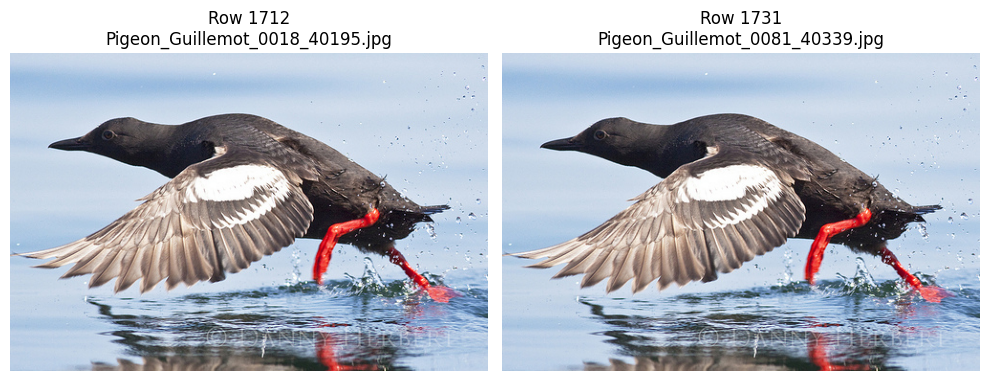

Unique captions in first record: 10
Unique captions in second record: 9
Shared captions: 0
Unique captions across both records: 19


In [17]:
pair = duplicate_image_groups[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, index in zip(axes, pair):
    record = raw_train[index]
    ax.imshow(record["image"].convert("RGB"))
    ax.set_title(f"Row {index}\n{record['file_name']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

captions_a = set(captions_by_image[pair[0]])
captions_b = set(captions_by_image[pair[1]])

print("Unique captions in first record:", len(captions_a))
print("Unique captions in second record:", len(captions_b))
print("Shared captions:", len(captions_a & captions_b))
print("Unique captions across both records:", len(captions_a | captions_b))

Purpose: To inspect the one pair of identical images and decide how to handle it.
What it does: Both images are displayed side by side, and their caption sets are compared (unique captions per record, shared captions, and combined unique captions).
Findings: The two images are visually identical but have different file names. Their caption sets share no captions, and together they contain 19 unique captions.
Conclusion: The duplicate has negligible effect on classification (one image in 5,994), but the two records carry independent annotations, so removing one would discard useful captioning data. Both are kept, and both are assigned to the training split so that identical images can never appear on both sides of the training/validation split.

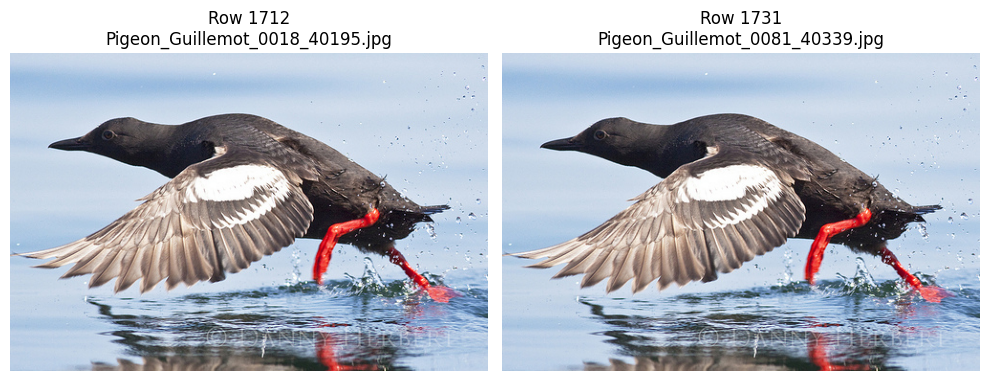

Unique captions in first record: 10
Unique captions in second record: 9
Shared captions: 0
Unique captions across both records: 19


In [18]:
pair = duplicate_image_groups[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, index in zip(axes, pair):
    record = raw_train[index]
    ax.imshow(record["image"].convert("RGB"))
    ax.set_title(f"Row {index}\n{record['file_name']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

captions_a = set(captions_by_image[pair[0]])
captions_b = set(captions_by_image[pair[1]])

print("Unique captions in first record:", len(captions_a))
print("Unique captions in second record:", len(captions_b))
print("Shared captions:", len(captions_a & captions_b))
print("Unique captions across both records:", len(captions_a | captions_b))

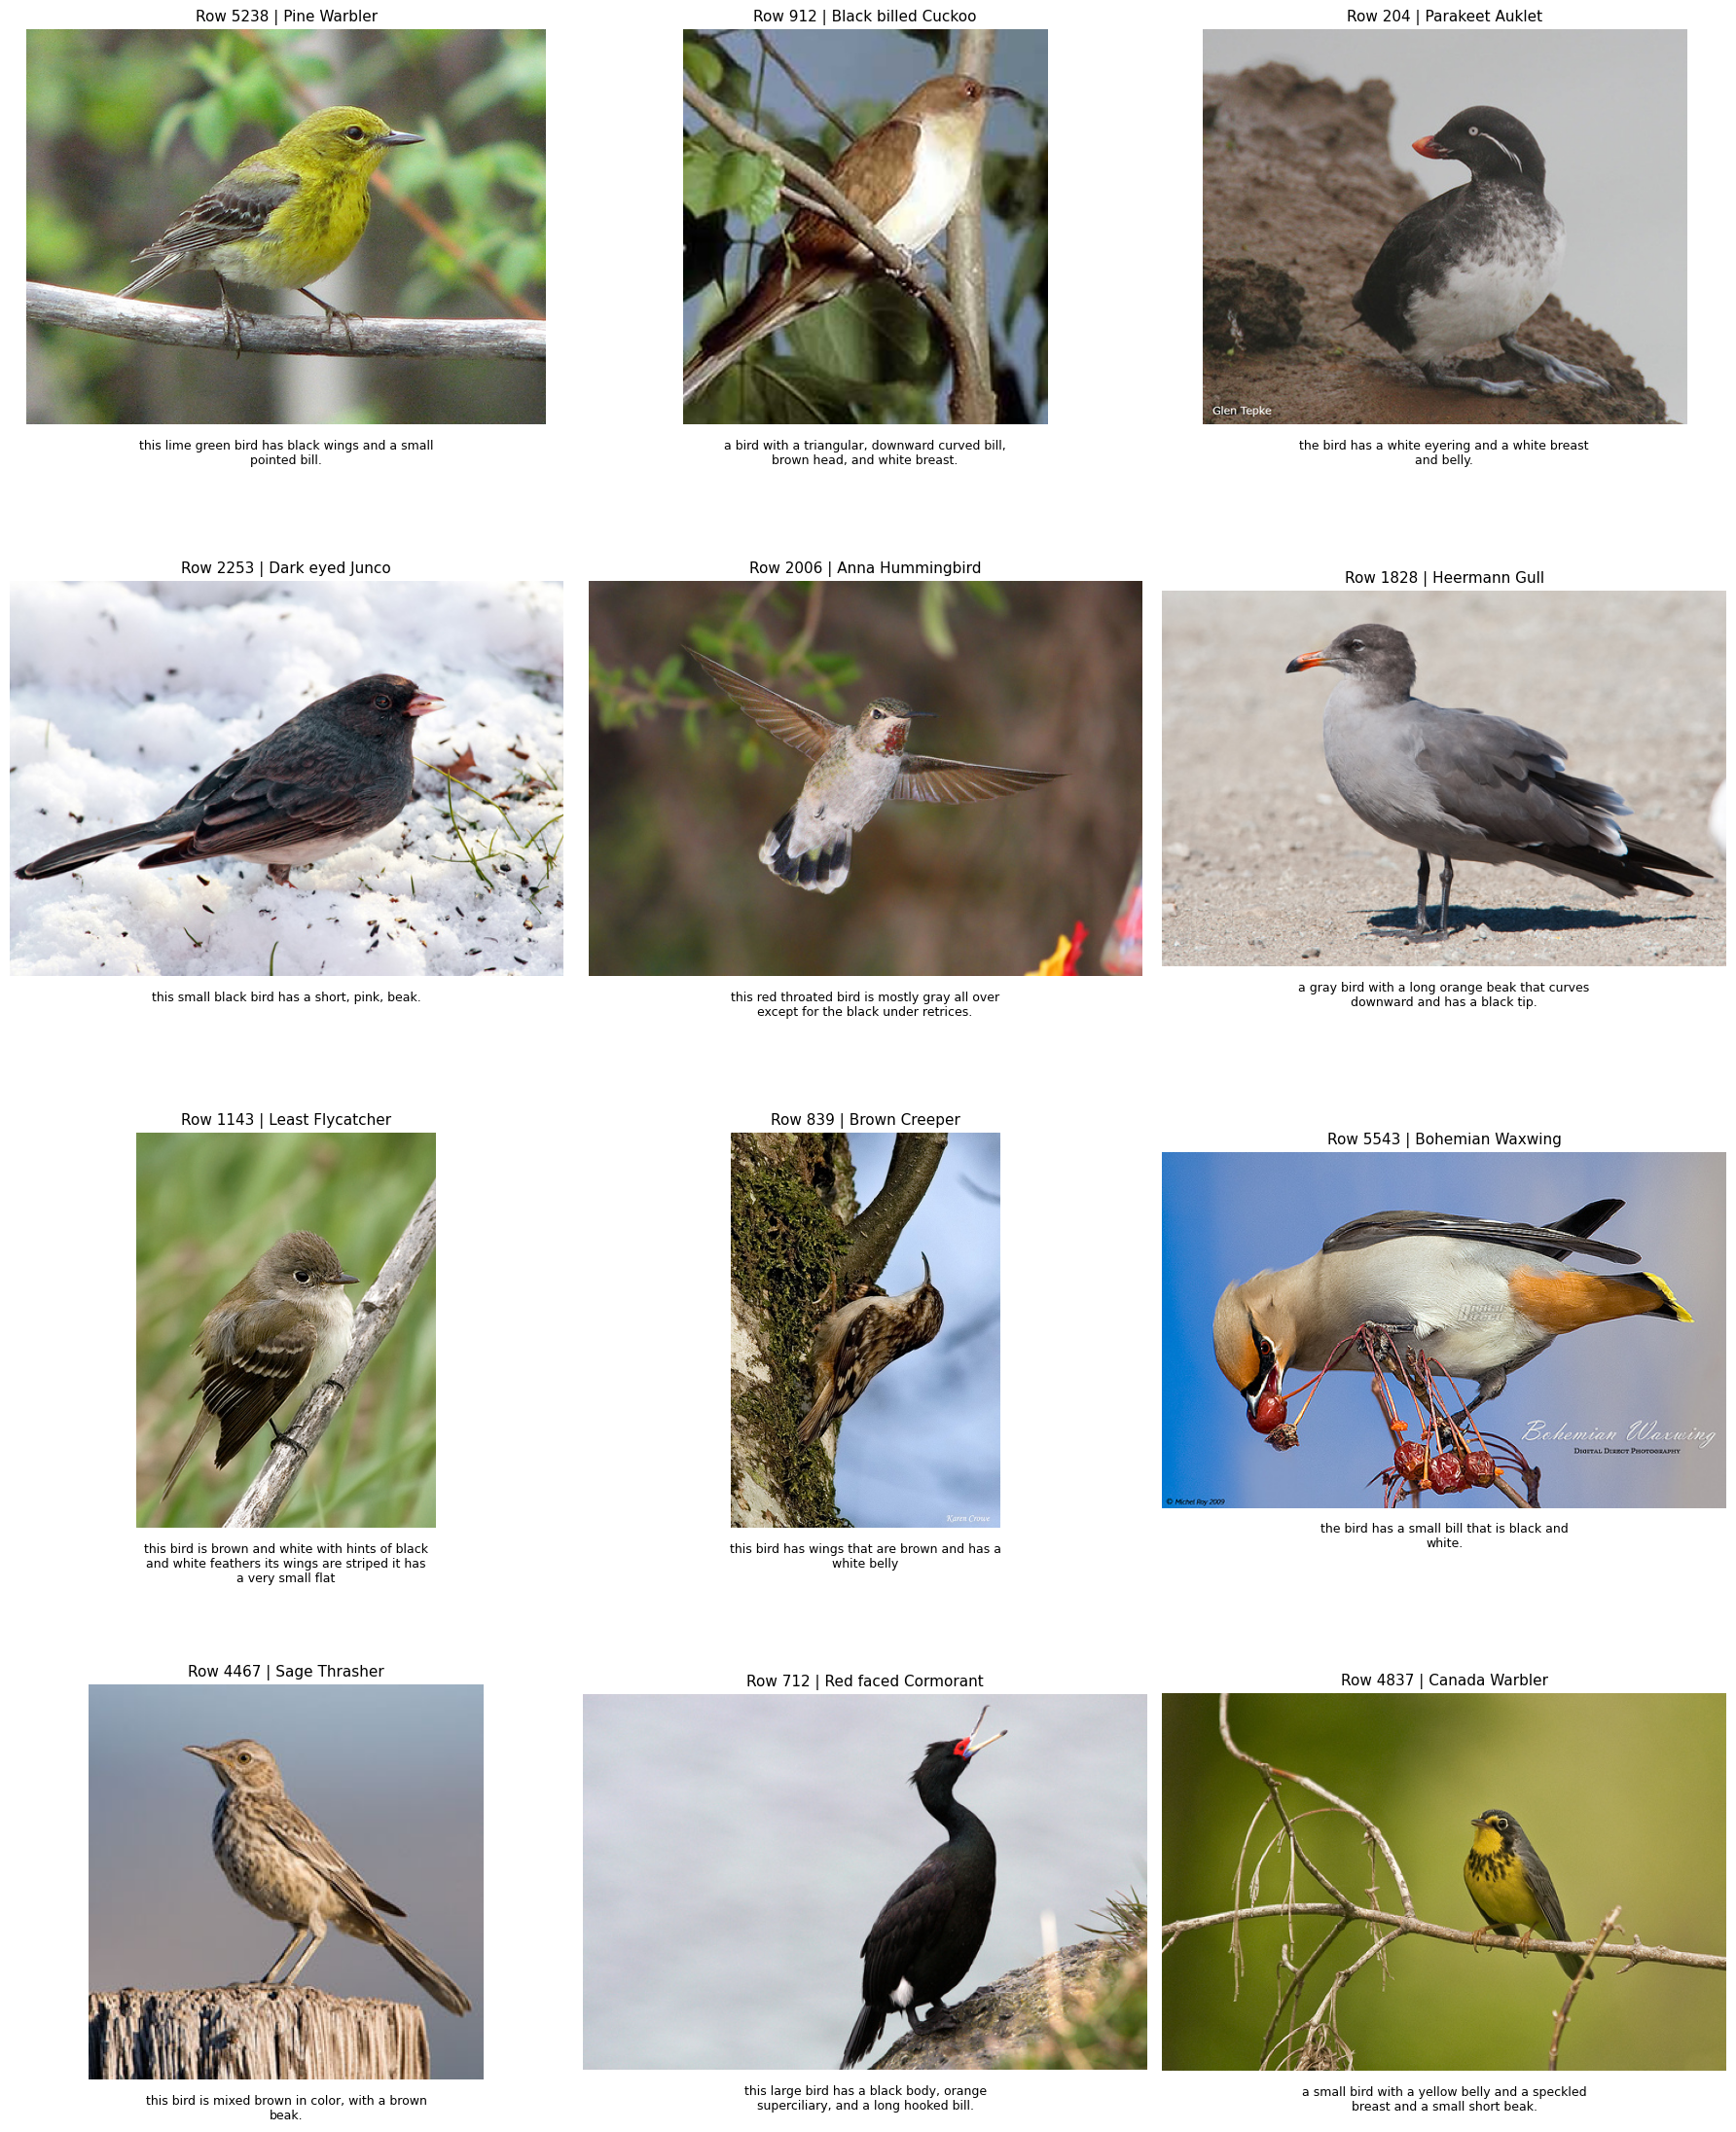

In [20]:
import random
import textwrap

rng = random.Random(42)
sample_indices = rng.sample(range(len(raw_train)), 12)

fig, axes = plt.subplots(4, 3, figsize=(18, 22))

for ax, index in zip(axes.flat, sample_indices):
    record = raw_train[index]
    species = raw_train.features["label"].int2str(record["label"])
    caption = rng.choice(captions_by_image[index])

    ax.imshow(record["image"].convert("RGB"))
    ax.set_title(f"Row {index} | {species}", fontsize=11)
    ax.axis("off")

    ax.text(
        0.5, -0.04,
        textwrap.fill(caption, width=48),
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=9,
    )

plt.tight_layout(h_pad=6)
plt.show()

Random-sample visual inspection
Twelve randomly selected images were inspected alongside their provided species labels and one caption per image.
- Appearance and pose vary: the sample includes perched, flying, feeding, and climbing birds. Bird size and position within the frame also vary.
- Backgrounds vary: images include vegetation, snow, rocks, sand, and sky. The Brown Creeper’s plumage blends into the tree, illustrating a challenging foreground–background distinction.
- Visual detail varies: some images show clear feather patterns, while others appear softer or less detailed at the displayed resolution. Small identifying features may become harder to distinguish after resizing.
- Captions often describe visible attributes, including colors, beaks, wings, and bellies. However, their precision and completeness vary. The Least Flycatcher caption ends with “a very small flat,” suggesting an incomplete description.
- Some images contain embedded text or photographer marks. The Bohemian Waxwing image explicitly includes its species name. This creates a potential shortcut: a classifier might use embedded text rather than bird appearance. This observation does not establish that a trained model actually uses that shortcut.
- Scope: this is a qualitative spot check. It does not verify every species label or establish the frequency of these issues across the dataset.

Preserve useful bird details when resizing and avoid aggressive cropping or color transformations initially. Retain raw captions and record questionable entries for review. Flag images containing embedded text, especially species names, for further inspection. Later, use Grad-CAM to investigate whether predictions rely on the bird, background, or text regions.